[2026-10-09 Fiddler](https://thefiddler.substack.com/p/how-fast-can-you-surf)
====================

Fiddler
-------
First, numerically calculate the location of a wave crest and plot that versus time to
see what we're dealing with.

And, visually, it looks like $x = \pi/2 + t - 1/2\cdot\sin 3t + 1/9\cdot\sin 6t$ is a
pretty good approximation and the slowest speed is at $t = 0$ and the fastest speed is
at $t = \pi/3$ and the average speed is $1$.

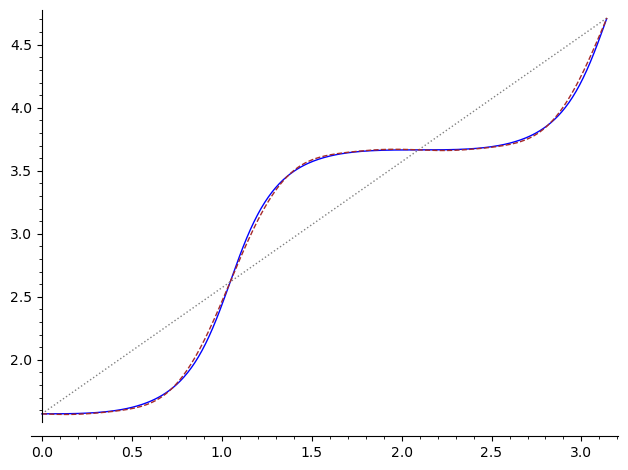

In [1]:
x,t = var("x,t")
y = 2*sin(x-t) + sin(x+2*t)

def xt(n,dt):
    xi = pi/2
    ti = 0
    for i in range(n):
        xi = find_root(derivative(y.substitute(t == ti)), xi - 8*dt, xi + 8*dt)
        yield (ti,xi)
        ti += dt

(line(xt(315,0.01))
 + plot(pi/2+t,t,0,pi,color="gray",linestyle="dotted")
 + plot(pi/2+t-1/2*sin(3*t)+1/9*sin(6*t)-1/40*sin(9*t),t,0,pi,color="brown",linestyle="dashed")
)

The position of the wave crest should satisfy $\frac{dy}{dx} = 2\cos(x-t) + \cos(x + 2t) = 0$,
giving

$$ x = \arctan\frac{\cos2t + 2\cos t}{\sin2t - 2\sin t} $$

for which $\frac{dx}{dt}$ has a minimum of $0$ and a maximum of $4$.

In [2]:
derivative(y, x).substitute(cos(x-t) == cos(x)*cos(t) + sin(x)*sin(t)). \
    substitute(cos(x+2*t) == cos(x)*cos(2*t) - sin(x)*sin(2*t))

cos(2*t)*cos(x) + 2*cos(t)*cos(x) - sin(2*t)*sin(x) + 2*sin(t)*sin(x)

In [3]:
xc = pi + arctan((cos(2*t) + 2*cos(t))/(sin(2*t) - 2*sin(t)))

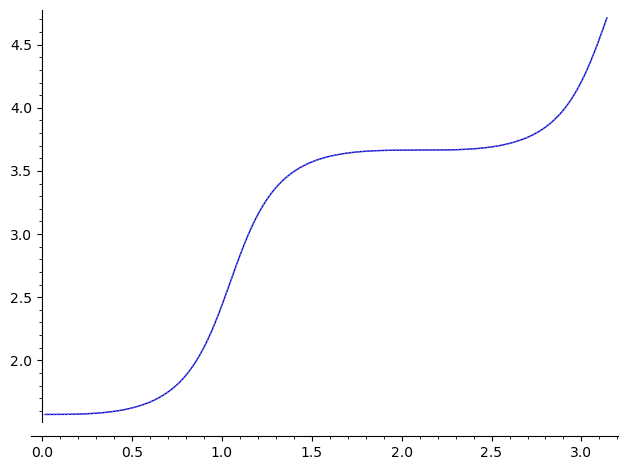

In [4]:
plot(xc, t, 0, pi) + line(xt(315,0.01), color="gray", linestyle="dotted")

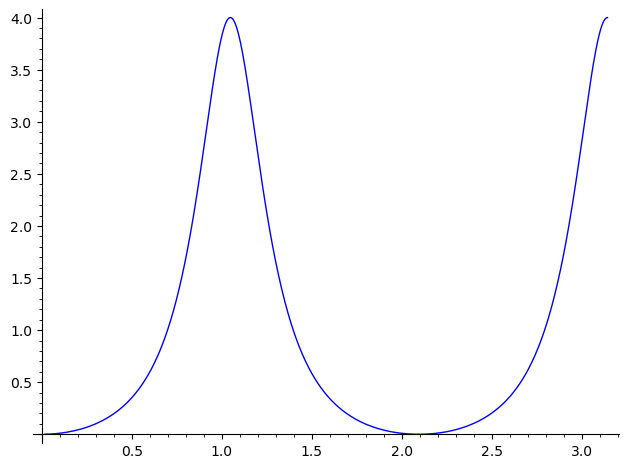

In [5]:
plot(derivative(xc,t),t,0,pi)

In [6]:
derivative(xc,t).substitute(t == pi/3), derivative(derivative(xc, t), t).substitute(t == pi/3), \
    derivative(derivative(derivative(xc,t),t),t).substitute(t == pi/3)

(4, 0, -162)

In [7]:
derivative(xc,t).substitute(t == 2*pi/3), derivative(derivative(xc, t), t).substitute(t == 2*pi/3), \
    derivative(derivative(derivative(xc,t),t),t).substitute(t == 2*pi/3)

(0, 0, 2)

Extra credit
------------
And averaging $\frac{dx}{dt}$ from $t = 0$ to $t = \pi$ gives $1$.

In [8]:
(xc.limit(t = pi, dir="-") - xc.limit(t = 0, dir="+"))/pi

1